# 23CSE301 – Machine Learning Capstone
## Clustering – NYC Yellow Taxi Trips

**Dataset:** NYC TLC Yellow Taxi Trip Records, January 2023 (random sample of 100,000 trips)

**Goal:** Group taxi trips into natural segments using **unsupervised learning**, without using fare as an input.

**Algorithms compared:**
1. **K-Means** (k chosen via the Elbow method)
2. **Agglomerative (Hierarchical) Clustering** with ward / complete / average linkage

**Evaluation (no labels available, so internal metrics are used):** Silhouette Score ↑, Davies-Bouldin Index ↓, Calinski-Harabasz Index ↑

**Pipeline:** Load & audit → Clean → Feature engineering → Scale/encode → PCA → K-Means → Agglomerative → Visualise (PCA 2D, t-SNE, dendrogram) → Compare.

### Library Imports
Core libraries for data handling and preprocessing. Some classifier imports are inherited from the shared project template and are not used in this clustering notebook.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

### Reproducibility
A fixed `RANDOM_STATE = 42` keeps sampling and clustering results identical across runs.

In [2]:
# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

---
## 1. Data Loading & Audit
Loads the January 2023 yellow-taxi Parquet file, samples **100,000 rows** for speed, and audits it: shape, data types, missing values, duplicates and the distribution of `fare_amount`.

In [3]:
# ==========================================
# 1. DATA LOADING & AUDIT
# ==========================================

# Path to the locally downloaded dataset
file_path = "yellow_tripdata_2023-01.parquet"

print("Loading NYC TLC Parquet data from local file...")

# Load the locally downloaded dataset
raw_df = pd.read_parquet(file_path)

# Randomly sample 100,000 records for computational efficiency
raw_df = raw_df.sample(
    n=100000,
    random_state=RANDOM_STATE
)

print("--- Raw Dataset Audit ---")

# Dataset shape
print(f"\nDataset Shape: {raw_df.shape}")

# Dataset information
print("\nDataset Information:")
raw_df.info()

# Data types
print("\nData Types:")
print(raw_df.dtypes)

# Missing values
print("\nMissing Values Count:")
print(raw_df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows Count:")
print(raw_df.duplicated().sum())

# Target distribution
print("\nTarget (Fare Amount) Distribution:")
print(raw_df["fare_amount"].describe())

print("\nFare Amount Value Counts (Top 10):")
print(raw_df["fare_amount"].value_counts().head(10))

Loading NYC TLC Parquet data from local file...
--- Raw Dataset Audit ---

Dataset Shape: (100000, 19)

Dataset Information:
<class 'pandas.DataFrame'>
Index: 100000 entries, 2790731 to 13812
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               100000 non-null  int64         
 1   tpep_pickup_datetime   100000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  100000 non-null  datetime64[us]
 3   passenger_count        97714 non-null   float64       
 4   trip_distance          100000 non-null  float64       
 5   RatecodeID             97714 non-null   float64       
 6   store_and_fwd_flag     97714 non-null   str           
 7   PULocationID           100000 non-null  int64         
 8   DOLocationID           100000 non-null  int64         
 9   payment_type           100000 non-null  int64         
 10  fare_amount            100000 non-null  float64   

**Preview of the data** – the first five rows of the sampled dataset.

In [4]:
print("\n--- First 5 Rows of the Dataset ---")
raw_df.head()


--- First 5 Rows of the Dataset ---


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
2790731,2,2023-01-29 17:52:02,2023-01-29 17:56:43,1.0,1.17,1.0,N,262,74,2,7.2,0.0,0.5,0.00,0.0,1.0,11.20,2.5,0.0
666153,1,2023-01-08 15:57:24,2023-01-08 16:02:47,1.0,0.90,1.0,N,229,237,2,6.5,2.5,0.5,0.00,0.0,1.0,10.50,2.5,0.0
1985683,2,2023-01-21 19:38:01,2023-01-21 19:45:02,1.0,0.95,1.0,N,45,261,1,7.9,0.0,0.5,2.38,0.0,1.0,14.28,2.5,0.0
2154231,2,2023-01-23 16:07:31,2023-01-23 16:26:46,5.0,0.88,1.0,N,237,141,1,16.3,2.5,0.5,1.50,0.0,1.0,24.30,2.5,0.0
2493619,2,2023-01-26 21:21:08,2023-01-26 21:24:48,2.0,1.03,1.0,N,229,140,1,6.5,1.0,0.5,2.30,0.0,1.0,13.80,2.5,0.0


---
## 2. Data Cleaning
- Parse pick-up / drop-off timestamps and create `trip_duration_min`.
- Remove duplicate rows.
- Filter unrealistic records: distance 0.1–100 miles, fare \$2.5–\$300, duration 1–180 minutes, 1–6 passengers.
- Impute missing values (median for numeric, mode for categorical).
- Convert ID-style columns (`RatecodeID`, `payment_type`) to categorical strings.

The summary shows how many records were removed and confirms that no missing values remain.

In [5]:
# ==========================================
# 2. DATA CLEANING
# ==========================================

df = raw_df.copy()

# Datetime Parsing & Duration
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

df['trip_duration_min'] = (
    (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime'])
    .dt.total_seconds() / 60.0
)

# Check and remove duplicate rows
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

# Outlier and invalid-value filtering
# Thresholds are chosen to remove clearly unrealistic records
# while retaining valid taxi trips.
df = df[
    (df['trip_distance'] > 0.1) & (df['trip_distance'] < 100) &
    (df['fare_amount'] > 2.5) & (df['fare_amount'] < 300) &
    (df['trip_duration_min'] > 1.0) & (df['trip_duration_min'] < 180) &
    (df['passenger_count'] > 0) & (df['passenger_count'] <= 6)
].copy()

# Fill missing numerical values using the median
df['congestion_surcharge'] = df['congestion_surcharge'].fillna(
    df['congestion_surcharge'].median()
)

df['airport_fee'] = df['airport_fee'].fillna(
    df['airport_fee'].median()
)

# Fill missing categorical values using the most frequent category
df['RatecodeID'] = df['RatecodeID'].fillna(
    df['RatecodeID'].mode()[0]
).astype(str)

df['store_and_fwd_flag'] = df['store_and_fwd_flag'].fillna(
    df['store_and_fwd_flag'].mode()[0]
)

# Convert categorical ID column to string
df['payment_type'] = df['payment_type'].astype(str)

print("\n--- Data Cleaning Summary ---")
print(f"Records before cleaning: {raw_df.shape[0]}")
print(f"Records after cleaning: {df.shape[0]}")
print(f"Records removed: {raw_df.shape[0] - df.shape[0]}")
print(f"Duplicate rows found: {duplicates_before}")

print("\nRemaining Missing Values:")
remaining_missing = df.isnull().sum()
print(remaining_missing[remaining_missing > 0])


--- Data Cleaning Summary ---
Records before cleaning: 100000
Records after cleaning: 93604
Records removed: 6396
Duplicate rows found: 0

Remaining Missing Values:
Series([], dtype: int64)


---
## 3. Feature Engineering
Creates `pickup_hour`, `day_of_week` and `is_weekend` from the pick-up timestamp, and defines the feature lists. Location IDs are treated as categorical variables.

In [6]:
# ==========================================
# 3. FEATURE ENGINEERING
# ==========================================
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['day_of_week'] = df['tpep_pickup_datetime'].dt.day_name()
df['is_weekend'] = df['tpep_pickup_datetime'].dt.dayofweek.isin([5, 6]).astype(int)

df['PULocationID'] = df['PULocationID'].astype(str)
df['DOLocationID'] = df['DOLocationID'].astype(str)

X = df[['PULocationID', 'DOLocationID', 'day_of_week',
        'passenger_count', 'trip_distance', 'trip_duration_min',
        'pickup_hour', 'is_weekend']]
y = df['fare_amount']

num_features = ['passenger_count', 'trip_distance', 'trip_duration_min', 'pickup_hour', 'is_weekend']
cat_features = ['PULocationID', 'DOLocationID', 'day_of_week']


---
## 4. Preprocessing & Train–Test Split (shared set-up)
This cell comes from the shared project template: it splits the data and fits the scaler/encoder on the training portion only. The clustering analysis below does **not** use this split – clustering is unsupervised, so it re-does the preprocessing on the full cleaned dataset (Section 6).

In [7]:
# ==========================================
# 4. PREPROCESSING & TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Categorical feature encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            sparse_output=False
        ), cat_features)
    ]
)

# Fit ONLY on Training Data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\n--- Pipeline Status ---")
print(f"Cleaned Dataset Shape: {df.shape}")
print(f"X_train Shape: {X_train_processed.shape}")
print(f"X_test Shape: {X_test_processed.shape}")


--- Pipeline Status ---
Cleaned Dataset Shape: (93604, 23)
X_train Shape: (74883, 450)
X_test Shape: (18721, 450)


C:\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


---
## 5. PCA on the Train/Test Split (shared set-up)
Applies PCA (95% variance) to the supervised-learning split. Kept for consistency with the classification notebooks; the clustering-specific PCA is done in Section 7.

In [8]:
# ==========================================
# 5. PCA DIMENSIONALITY REDUCTION
# ==========================================

from sklearn.decomposition import PCA

pca = PCA(
    n_components=0.95,
    random_state=RANDOM_STATE
)

X_train_reduced = pca.fit_transform(X_train_processed)
X_test_reduced = pca.transform(X_test_processed)

print("\n--- PCA Dimensionality Reduction ---")
print(f"Original number of features: {X_train_processed.shape[1]}")
print(f"Reduced number of features: {X_train_reduced.shape[1]}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.4f}")


--- PCA Dimensionality Reduction ---
Original number of features: 450
Reduced number of features: 75
Variance retained: 0.9509


---
## 6. Clustering Preprocessing
Clustering needs no train-test split, so the **whole cleaned dataset** is used.
- The input features are the same trip characteristics (location IDs, day, passengers, distance, duration, hour, weekend flag).
- **`fare_amount` is deliberately excluded** from the clustering features and stored separately, so it can be used later purely to *interpret* what each cluster represents.
- Numeric features are standardised and categorical features one-hot encoded, so that no feature dominates the distance calculations.

In [9]:

# ==========================================
# 4. CLUSTERING PREPROCESSING
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Clustering does not require a train-test split
X_cluster = df[
    [
        'PULocationID',
        'DOLocationID',
        'day_of_week',
        'passenger_count',
        'trip_distance',
        'trip_duration_min',
        'pickup_hour',
        'is_weekend'
    ]
].copy()

# Keep fare separately for interpretation only
fare_for_interpretation = df['fare_amount'].copy()

num_features = [
    'passenger_count',
    'trip_distance',
    'trip_duration_min',
    'pickup_hour',
    'is_weekend'
]

cat_features = [
    'PULocationID',
    'DOLocationID',
    'day_of_week'
]

preprocessor_cluster = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            sparse_output=False
        ), cat_features)
    ]
)

X_cluster_processed = preprocessor_cluster.fit_transform(X_cluster)

print("Clustering preprocessing complete.")
print(f"Clustering data shape: {X_cluster_processed.shape}")
print(f"Fare kept separately: {fare_for_interpretation.shape}")


Clustering preprocessing complete.
Clustering data shape: (93604, 462)
Fare kept separately: (93604,)


Quick check of the train/test PCA array shapes from Section 5 (for reference only).

In [10]:
print("PCA training data shape:", X_train_reduced.shape)
print("PCA testing data shape:", X_test_reduced.shape)

PCA training data shape: (74883, 75)
PCA testing data shape: (18721, 75)


---
## 7. PCA for Clustering
Two PCA versions are created:
- **95%-variance PCA** (75 components) – the input used by the clustering algorithms. This removes noise and speeds up distance calculations on the wide one-hot-encoded data.
- **2-component PCA** – used only to draw 2D scatter plots. These two components explain only about 40% of the variance, so the 2D plots are a simplified picture of the real cluster structure.

In [11]:

# ==========================================
# PCA FOR CLUSTERING
# ==========================================

from sklearn.decomposition import PCA

# PCA retaining 95% of variance
pca_cluster = PCA(
    n_components=0.95,
    random_state=RANDOM_STATE
)

X_cluster_pca = pca_cluster.fit_transform(
    X_cluster_processed
)

print("Clustering PCA shape:", X_cluster_pca.shape)
print(
    "Explained variance retained:",
    round(pca_cluster.explained_variance_ratio_.sum(), 4)
)

# Separate 2D PCA for cluster visualization
pca_cluster_2d = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_cluster_pca_2d = pca_cluster_2d.fit_transform(
    X_cluster_processed
)

print("2D visualization shape:", X_cluster_pca_2d.shape)
print(
    "Variance explained by first 2 components:",
    round(pca_cluster_2d.explained_variance_ratio_.sum(), 4)
)


Clustering PCA shape: (93604, 75)
Explained variance retained: 0.951
2D visualization shape: (93604, 2)
Variance explained by first 2 components: 0.3985


---
## Model 1: K-Means – Choosing k with the Elbow Method
K-Means assigns each point to the nearest of *k* centroids and iteratively updates the centroids to minimise within-cluster variance (inertia).

To pick *k*, K-Means is run for k = 2 … 10 on a reproducible 15,000-row sample, and the **inertia** is plotted against k. The "elbow" – where adding more clusters stops giving large improvements – indicates a reasonable k. Here the curve bends gradually rather than sharply, so k = 4 is chosen as a balance between compactness and interpretability.

Fitting K-Means with k=2...
Fitting K-Means with k=3...
Fitting K-Means with k=4...
Fitting K-Means with k=5...
Fitting K-Means with k=6...
Fitting K-Means with k=7...
Fitting K-Means with k=8...
Fitting K-Means with k=9...
Fitting K-Means with k=10...


,Number of Clusters (k),Inertia
0,2,90701.643244
1,3,74973.526919
2,4,66339.000541
3,5,61218.182503
4,6,57389.059100
5,7,54663.367756
6,8,53406.283383
7,9,51985.657377
8,10,50650.673367


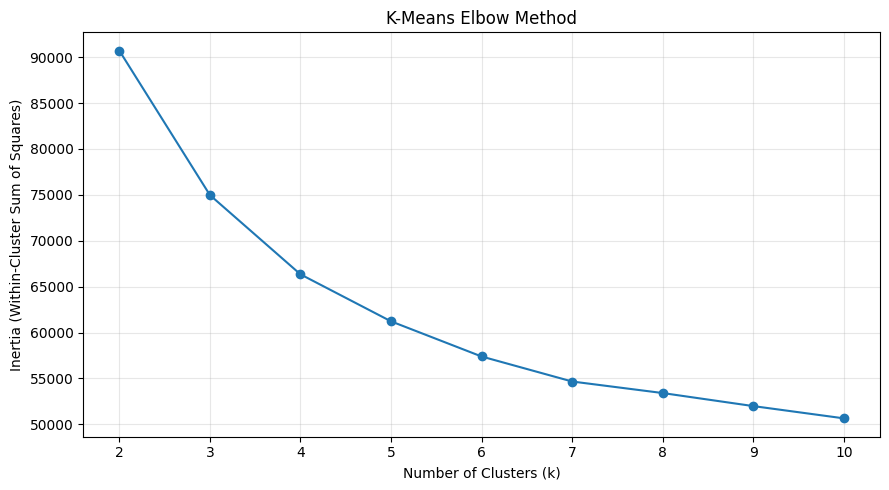

In [12]:

# ==========================================
# MODEL 1: K-MEANS — ELBOW METHOD
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split

# Use a reproducible sample for faster clustering
SAMPLE_SIZE = min(15000, X_cluster_pca.shape[0])

X_kmeans_sample, _ = train_test_split(
    X_cluster_pca,
    train_size=SAMPLE_SIZE,
    random_state=RANDOM_STATE
)

# Test different numbers of clusters
k_values = range(2, 11)
inertias = []

for k in k_values:
    print(f"Fitting K-Means with k={k}...")

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    model.fit(X_kmeans_sample)
    inertias.append(model.inertia_)

# Store results
elbow_results = pd.DataFrame({
    'Number of Clusters (k)': list(k_values),
    'Inertia': inertias
})

display(elbow_results)

# Plot Elbow curve
plt.figure(figsize=(9, 5))
plt.plot(
    list(k_values),
    inertias,
    marker='o'
)

plt.title('K-Means Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### K-Means with k = 4
K-Means is fitted with k = 4 and evaluated with three internal metrics:
- **Silhouette Score** (−1 to 1, higher is better) – how well each point fits its own cluster compared with the nearest other cluster
- **Davies-Bouldin Index** (lower is better) – average similarity between each cluster and its most similar neighbour
- **Calinski-Harabasz Index** (higher is better) – ratio of between-cluster to within-cluster dispersion

The clusters are then plotted on the 2D PCA projection.

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,4,0.2451,1.4288,3342.478


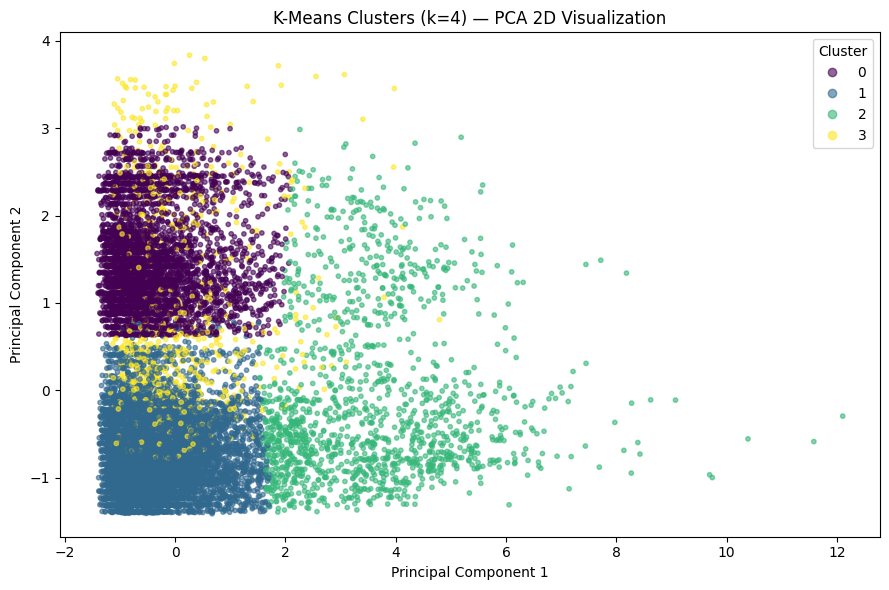

In [13]:

# ==========================================
# K-MEANS CLUSTERING WITH k=4
# ==========================================

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd
import matplotlib.pyplot as plt

# Fit K-Means on the sample used for the Elbow curve
kmeans = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_kmeans_sample)

# ==========================================
# EVALUATION METRICS
# ==========================================

sil_score = silhouette_score(
    X_kmeans_sample,
    kmeans_labels,
    sample_size=min(5000, len(kmeans_labels)),
    random_state=RANDOM_STATE
)

db_score = davies_bouldin_score(
    X_kmeans_sample,
    kmeans_labels
)

ch_score = calinski_harabasz_score(
    X_kmeans_sample,
    kmeans_labels
)

kmeans_results = pd.DataFrame([{
    'Algorithm': 'K-Means',
    'Number of Clusters': 4,
    'Silhouette Score': sil_score,
    'Davies-Bouldin Index': db_score,
    'Calinski-Harabasz Index': ch_score
}])

display(kmeans_results.round(4))

# ==========================================
# 2D PCA CLUSTER VISUALIZATION
# ==========================================

# Match the sample indices used for clustering
sample_indices = X_cluster_pca.shape[0]

# Recreate the same deterministic sample indices
from sklearn.model_selection import train_test_split
all_indices = list(range(sample_indices))

sample_idx, _ = train_test_split(
    all_indices,
    train_size=min(15000, sample_indices),
    random_state=RANDOM_STATE
)

X_kmeans_2d = X_cluster_pca_2d[sample_idx]

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_kmeans_2d[:, 0],
    X_kmeans_2d[:, 1],
    c=kmeans_labels,
    s=10,
    alpha=0.6
)

plt.title('K-Means Clusters (k=4) — PCA 2D Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(
    *scatter.legend_elements(),
    title='Cluster'
)
plt.tight_layout()
plt.show()


---
## Model 2: Agglomerative (Hierarchical) Clustering
A bottom-up method: every point starts as its own cluster and the closest clusters are merged step by step. The **linkage** rule decides how cluster distance is measured:
- **Ward** – merges the pair that least increases within-cluster variance
- **Complete** – uses the maximum distance between points of two clusters
- **Average** – uses the mean distance between all point pairs

All three are tested with 4 clusters on the same 15,000-row sample and compared using the same three metrics (silhouette computed on a 5,000-point sample for speed).

In [14]:

# ==========================================
# MODEL 2: AGGLOMERATIVE CLUSTERING
# LINKAGE COMPARISON
# ==========================================

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd

linkage_options = ['ward', 'complete', 'average']
agg_results = []

for linkage in linkage_options:
    print(f"Testing linkage: {linkage}...")

    model = AgglomerativeClustering(
        n_clusters=4,
        linkage=linkage
    )

    labels_agg = model.fit_predict(X_kmeans_sample)

    # Sampled silhouette score for speed
    sil = silhouette_score(
        X_kmeans_sample,
        labels_agg,
        sample_size=min(5000, len(labels_agg)),
        random_state=RANDOM_STATE
    )

    db = davies_bouldin_score(
        X_kmeans_sample,
        labels_agg
    )

    ch = calinski_harabasz_score(
        X_kmeans_sample,
        labels_agg
    )

    agg_results.append({
        'Linkage': linkage,
        'Number of Clusters': 4,
        'Silhouette Score': sil,
        'Davies-Bouldin Index': db,
        'Calinski-Harabasz Index': ch
    })

agg_results = pd.DataFrame(agg_results)

display(agg_results.round(4))


Testing linkage: ward...
Testing linkage: complete...
Testing linkage: average...


,Linkage,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,4,0.2251,1.4967,2871.3747
1,complete,4,0.3570,1.7962,998.1340
2,average,4,0.3885,0.7552,971.8101


### Agglomerative Clustering – PCA 2D Visualisation
Average linkage gave the best Silhouette Score and Davies-Bouldin Index in the comparison above, so it is used for the final model. The resulting 4 clusters are shown on the 2D PCA projection.

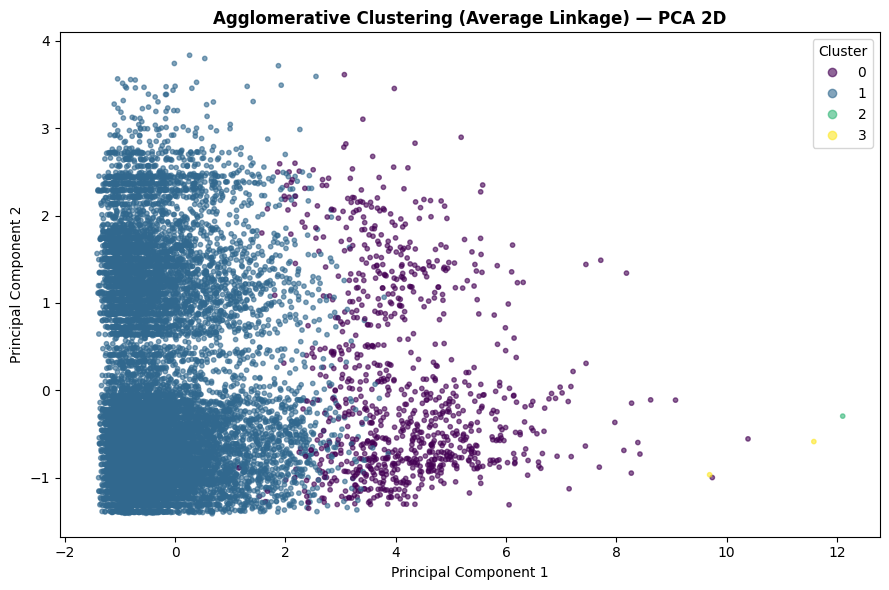

In [15]:

# ==========================================
# AGGLOMERATIVE CLUSTERING: PCA 2D VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

# Average linkage performed best on Silhouette
# and Davies-Bouldin metrics
agg_final = AgglomerativeClustering(
    n_clusters=4,
    linkage='average'
)

agg_labels = agg_final.fit_predict(X_kmeans_sample)

# Use the same sample indices for the 2D PCA plot
# X_kmeans_sample was selected from X_cluster_pca
from sklearn.model_selection import train_test_split

all_indices = list(range(X_cluster_pca.shape[0]))

sample_idx, _ = train_test_split(
    all_indices,
    train_size=min(15000, len(all_indices)),
    random_state=RANDOM_STATE
)

X_agg_2d = X_cluster_pca_2d[sample_idx]

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_agg_2d[:, 0],
    X_agg_2d[:, 1],
    c=agg_labels,
    s=10,
    alpha=0.6
)

plt.title(
    'Agglomerative Clustering (Average Linkage) — PCA 2D',
    fontweight='bold'
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(
    *scatter.legend_elements(),
    title='Cluster'
)

plt.tight_layout()
plt.show()


---
## t-SNE Visualisation of K-Means Clusters
**t-SNE** is a non-linear technique that preserves local neighbourhoods, so it often separates clusters more clearly than linear PCA. Because it is computationally expensive, it is run on only 3,000 observations (K-Means with k = 4 is refitted on the same points). Distances *between* far-apart groups in a t-SNE plot should not be over-interpreted.

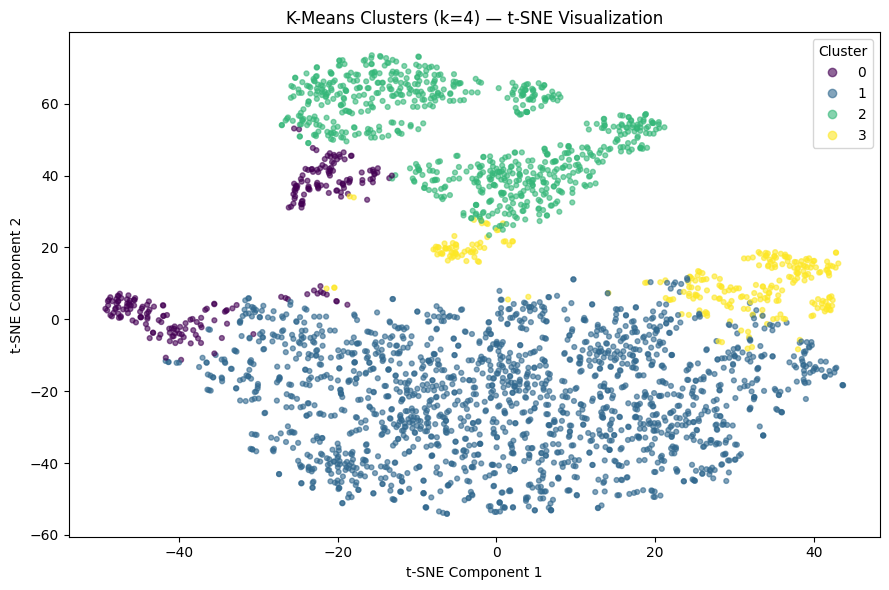

In [16]:

# ==========================================
# T-SNE VISUALIZATION FOR K-MEANS
# ==========================================

from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Use 3,000 observations to keep t-SNE manageable
TSNE_SIZE = min(3000, len(X_kmeans_sample))

X_tsne_input = X_kmeans_sample[:TSNE_SIZE]

# Fit K-Means on the same observations
kmeans_tsne = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10
)

labels_tsne = kmeans_tsne.fit_predict(X_tsne_input)

# Reduce to two dimensions using t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=RANDOM_STATE
)

X_tsne_2d = tsne.fit_transform(X_tsne_input)

# Plot t-SNE visualization
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne_2d[:, 0],
    X_tsne_2d[:, 1],
    c=labels_tsne,
    s=12,
    alpha=0.6
)

plt.title('K-Means Clusters (k=4) — t-SNE Visualization')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')

plt.legend(
    *scatter.legend_elements(),
    title='Cluster'
)

plt.tight_layout()
plt.show()


---
## Final Clustering Comparison
Side-by-side metrics for K-Means and Agglomerative (average linkage).

| Metric | Better when | Observation |
|--------|-------------|-------------|
| Silhouette | Higher | Agglomerative (average) scores higher |
| Davies-Bouldin | Lower | Agglomerative (average) is lower, i.e. better |
| Calinski-Harabasz | Higher | K-Means scores higher |

The metrics disagree, so no single algorithm wins on all three.

In [17]:

# ==========================================
# FINAL CLUSTERING COMPARISON
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

clustering_comparison = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'Silhouette Score': sil_score,
        'Davies-Bouldin Index': db_score,
        'Calinski-Harabasz Index': ch_score
    },
    {
        'Algorithm': 'Agglomerative (Average)',
        'Silhouette Score': agg_results.loc[
            agg_results['Linkage'] == 'average',
            'Silhouette Score'
        ].iloc[0],
        'Davies-Bouldin Index': agg_results.loc[
            agg_results['Linkage'] == 'average',
            'Davies-Bouldin Index'
        ].iloc[0],
        'Calinski-Harabasz Index': agg_results.loc[
            agg_results['Linkage'] == 'average',
            'Calinski-Harabasz Index'
        ].iloc[0]
    }
])

print("Clustering Algorithm Comparison")
display(clustering_comparison.round(4))


Clustering Algorithm Comparison


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.2451,1.4288,3342.4780
1,Agglomerative (Average),0.3885,0.7552,971.8101


**Metric bar plots** – one chart per metric, each titled with whether higher or lower is better.

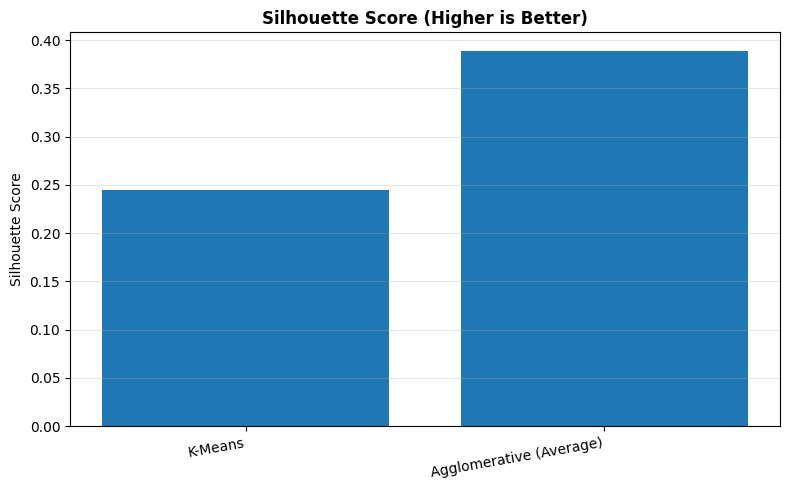

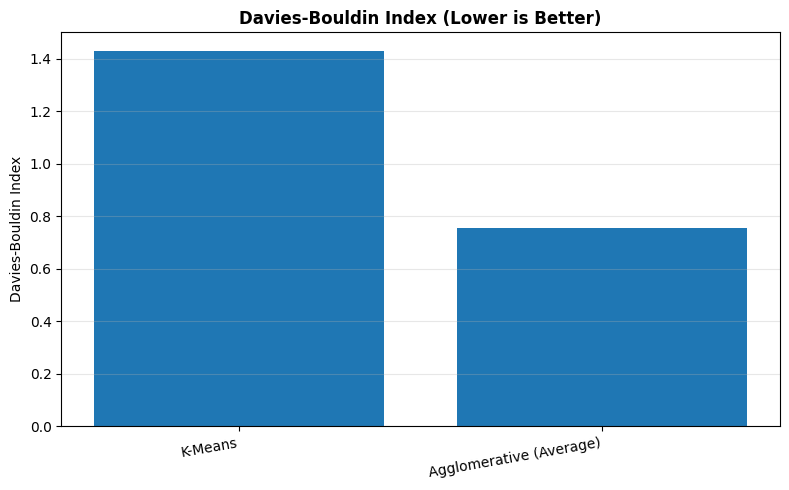

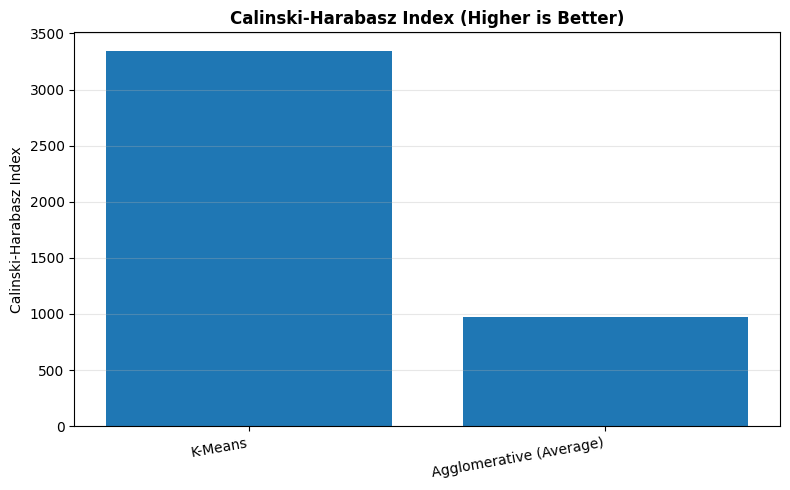

In [18]:

# ==========================================
# CLUSTERING METRIC COMPARISON PLOTS
# ==========================================

metrics_to_plot = [
    ('Silhouette Score', 'Silhouette Score (Higher is Better)'),
    ('Davies-Bouldin Index', 'Davies-Bouldin Index (Lower is Better)'),
    ('Calinski-Harabasz Index', 'Calinski-Harabasz Index (Higher is Better)')
]

for metric, title in metrics_to_plot:

    plt.figure(figsize=(8, 5))

    plt.bar(
        clustering_comparison['Algorithm'],
        clustering_comparison[metric]
    )

    plt.title(title, fontweight='bold')
    plt.ylabel(metric)
    plt.xticks(rotation=10, ha='right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


---
## Dendrogram (Hierarchical Structure)
A dendrogram shows the order and distance at which clusters were merged. It is drawn with **Ward linkage** on a 500-point sample and truncated to the last 30 merges to stay readable. Long vertical lines indicate merges between very different clusters, which helps justify the choice of number of clusters (a horizontal cut across the long lines gives the cluster count).

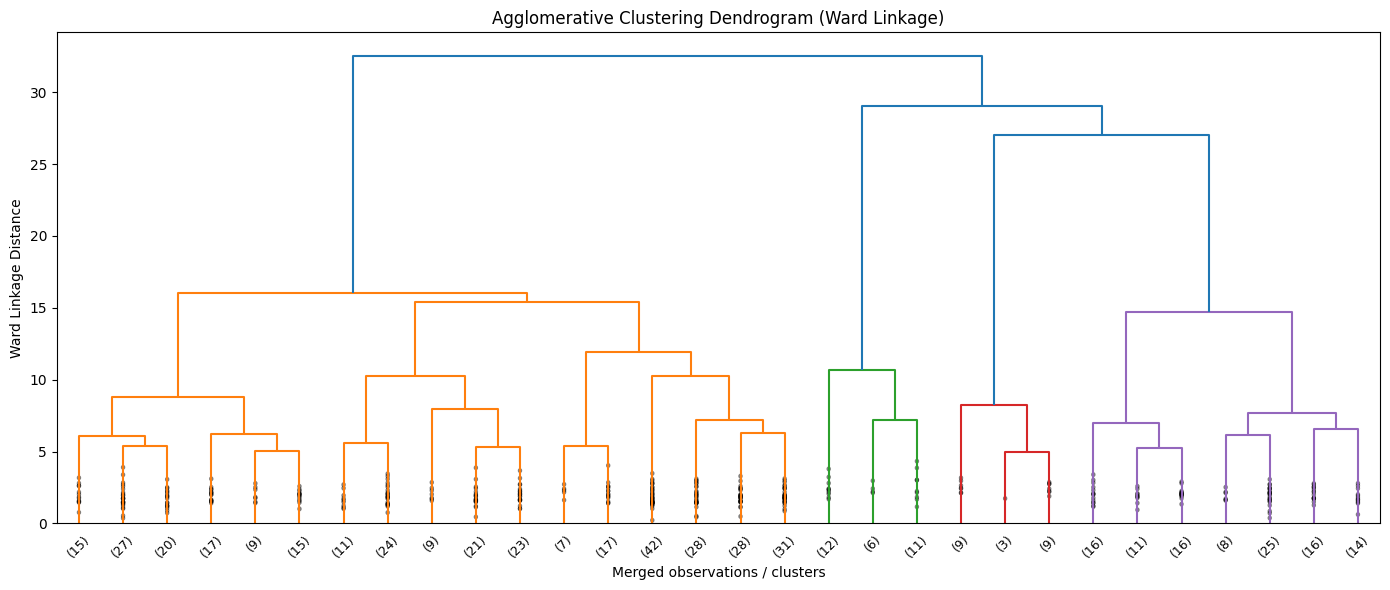

In [19]:

# ==========================================
# AGGLOMERATIVE CLUSTERING: DENDROGRAM
# ==========================================

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import train_test_split

# Use a smaller sample for the dendrogram
DENDROGRAM_SIZE = min(500, len(X_kmeans_sample))

X_dendrogram, _ = train_test_split(
    X_kmeans_sample,
    train_size=DENDROGRAM_SIZE,
    random_state=RANDOM_STATE
)

# Perform hierarchical linkage
Z = linkage(X_dendrogram, method='ward')

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=45,
    leaf_font_size=9,
    show_contracted=True
)

plt.title('Agglomerative Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Merged observations / clusters')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()


---
## Summary of Findings
- Preprocessing: 93,604 cleaned trips; features were standardised/one-hot encoded and reduced with PCA (75 components, ~95% variance).
- **K-Means (k = 4):** Silhouette ≈ 0.245, Davies-Bouldin ≈ 1.43, Calinski-Harabasz ≈ 3,342.
- **Agglomerative (average linkage, 4 clusters):** Silhouette ≈ 0.389, Davies-Bouldin ≈ 0.755, Calinski-Harabasz ≈ 972.
- Among the linkage options, **average** was best on Silhouette and Davies-Bouldin, while **ward** had the highest Calinski-Harabasz.
- Agglomerative (average) looks better on two of the three metrics, but average linkage can produce one very large cluster and a few tiny ones, which inflates Silhouette/Davies-Bouldin. It is worth checking the cluster sizes (`np.bincount(agg_labels)`) before concluding it gives more meaningful trip segments than K-Means.
- Since `fare_amount` was kept out of the clustering, a natural next step is to profile each cluster (mean fare, distance, duration, hour) to describe what type of trip each cluster represents.